In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import torch
import torch.nn as nn
import matplotlib.pyplot as plt

Tensor: tensor([ 2.,  4.,  6.,  8., 10.])
y = 42.0 | dy/dx = 13.0
Epoch 200, Loss: 0.000008
Epoch 400, Loss: 0.000001
Epoch 600, Loss: 0.000000
Epoch 800, Loss: 0.000000
Epoch 1000, Loss: 0.000000
Prediction for x=5: 11.0000 (Expected: 11.0)


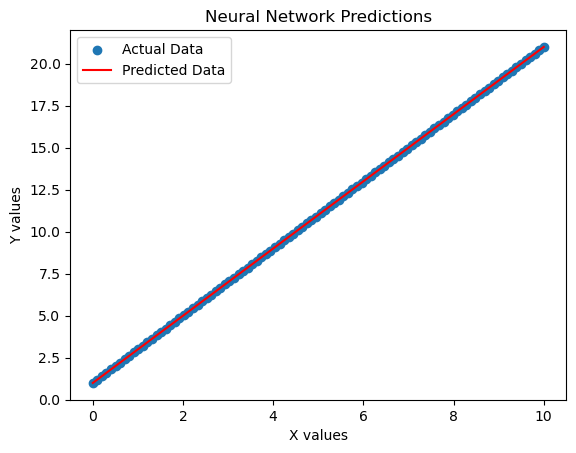

In [3]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# Exercise 1: Create Tensor
data = torch.tensor([2.0, 4.0, 6.0, 8.0, 10.0])
print("Tensor:", data)

# Exercise 2: Autograd for y = x^2 + 3x + 2 at x = 5
x = torch.tensor(5.0, requires_grad=True)
y = x**2 + 3*x + 2
y.backward()
print("y =", y.item(), "| dy/dx =", x.grad.item())  # Expected: 42.0, 13.0

# Exercise 3: Train SimpleNN on y = 2x + 1
torch.manual_seed(42)
X = torch.linspace(0, 10, 100).reshape(-1, 1)
Y = 2 * X + 1

class SimpleNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer = nn.Linear(1, 1)
    def forward(self, x):
        return self.layer(x)

model = SimpleNN()
loss_fn = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

for epoch in range(1000):
    predictions = model(X)
    loss = loss_fn(predictions, Y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    if (epoch + 1) % 200 == 0:
        print(f"Epoch {epoch+1}, Loss: {loss.item():.6f}")

test_pred = model(torch.tensor([[5.0]])).item()
print(f"Prediction for x=5: {test_pred:.4f} (Expected: 11.0)")

# Exercise 4: Visualize Predictions
with torch.no_grad():
    pred_vals = model(X)

plt.scatter(X.numpy(), Y.numpy(), label="Actual Data")
plt.plot(X.numpy(), pred_vals.numpy(), color="red", label="Predicted Data")
plt.xlabel("X values")
plt.ylabel("Y values")
plt.title("Neural Network Predictions")
plt.legend()
plt.show()